# Notebook 05 — Module 5: Machine-learning baselines with spatial cross-validation
**Input:** `features_cell_level.parquet`, `target_annulus_composition.parquet` and `src/spatialml` from Notebooks 03–04.
**Task:** predict the microenvironment class of a cell (50–100 µm ring) from its own neighborhood (≤ 30 µm), evaluated on **spatially held-out tissue blocks with a 100 µm buffer**.

**What Notebook 04 told us, and how it shapes this notebook**

| Finding in Notebook 04 | Consequence here |
|---|---|
| Most association disappears within a cell type (median η² 0.013–0.05 vs 0.124 overall) | The key baseline is a **cross-validated own-cell-type lookup**, not the majority class |
| Morphology was *not* a clean negative control (η² ≈ 0.10) | Morphology is kept out of "spatial" and tested only as a separate ablation |
| Classes lie along an epithelial gradient; the middle class has the lowest margin | Report **ordinal error**, boundary-cell analysis, and a **continuous regression** task |

**Model ladder (simple → complex):** majority → own-type lookup → logistic regression → random forest → histogram gradient boosting.
**Not in this notebook:** expression features and coordinate/leakage stress tests — those are Module 6.

**Order:** 0 Setup · 1 Data & design · 2 Unit tests · 3 Train with spatial CV · 4 Results & bootstrap comparisons · 5 Per-class / boundary / error map · 6 Regression · 7 Feature importance · 8 Save

In [1]:
import os, json, time, warnings, sys, importlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score, log_loss
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*bottleneck.*")
warnings.filterwarnings("ignore", message=".*X does not have valid feature names.*")
warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/spatial_ml_breast_cancer")
except ImportError:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./spatial_ml_breast_cancer"))

for sub in ["results/figures", "results/tables", "reports", "src/spatialml", "data/processed"]:
    (PROJECT_DIR / sub).mkdir(parents=True, exist_ok=True)
FIG_DIR, TAB_DIR, REP_DIR, PROC_DIR = (PROJECT_DIR / p for p in ["results/figures", "results/tables", "reports", "data/processed"])
CKPT = PROC_DIR / "ml_checkpoints"; CKPT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

CONFIG = json.load(open(PROJECT_DIR / "configs/config.json"))
SEED = CONFIG["seed"]; RNG = np.random.default_rng(SEED)
TD = CONFIG["target_design"]
CONFIG.setdefault("notebook05", {
    "max_train_cells": 80000,
    "tune_hgb": True,
    "hgb_grid": [
        {"learning_rate": 0.05, "max_leaf_nodes": 15, "max_iter": 200, "l2_regularization": 1.0, "min_samples_leaf": 100},
        {"learning_rate": 0.10, "max_leaf_nodes": 15, "max_iter": 150, "l2_regularization": 1.0, "min_samples_leaf": 100},
        {"learning_rate": 0.05, "max_leaf_nodes": 31, "max_iter": 200, "l2_regularization": 5.0, "min_samples_leaf": 200},
        {"learning_rate": 0.10, "max_leaf_nodes": 31, "max_iter": 100, "l2_regularization": 5.0, "min_samples_leaf": 200},
    ],
    "rf": {"n_estimators": 200, "min_samples_leaf": 20, "max_samples": 0.4},
    "logreg_C": 1.0, "ridge_alpha": 10.0,
    "n_bootstrap": 1000, "spearman_bootstrap": 100,
    "perm_cells_per_fold": 20000, "perm_repeats": 3,
})
N5 = CONFIG["notebook05"]

Mounted at /content/drive


In [2]:
SRC = r'''"""spatialml.modeling - leakage-safe model builders, block-bootstrap metrics, group permutation importance (Module 5)."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

LOG_PREFIXES = ("dist_nearest_", "knn_dist_", "mean_nbr_dist_", "n_cells_", "density_")


class TypeLookup(BaseEstimator, ClassifierMixin):
    """Class probabilities from the cell's own type only (one-hot columns). The baseline spatial features must beat."""
    def __init__(self, type_cols=None, alpha=1.0):
        self.type_cols = type_cols; self.alpha = alpha

    def fit(self, X, y):
        cols = list(self.type_cols); y = np.asarray(y)
        self.classes_ = np.unique(y); K = len(self.classes_)
        t = pd.DataFrame(X)[cols].to_numpy().argmax(1)
        counts = np.zeros((len(cols), K))
        np.add.at(counts, (t, np.searchsorted(self.classes_, y)), 1)
        self.table_ = (counts + self.alpha) / (counts.sum(1, keepdims=True) + self.alpha * K)
        return self

    def predict_proba(self, X):
        return self.table_[pd.DataFrame(X)[list(self.type_cols)].to_numpy().argmax(1)]

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


class TypeMean(BaseEstimator, RegressorMixin):
    """Mean of a continuous target per own cell type (regression baseline)."""
    def __init__(self, type_cols=None):
        self.type_cols = type_cols

    def fit(self, X, y):
        cols = list(self.type_cols); y = np.asarray(y, float)
        t = pd.DataFrame(X)[cols].to_numpy().argmax(1)
        self.means_ = np.array([y[t == k].mean() if (t == k).any() else y.mean() for k in range(len(cols))])
        return self

    def predict(self, X):
        return self.means_[pd.DataFrame(X)[list(self.type_cols)].to_numpy().argmax(1)]


def _linear_prep(cols):
    logc = [c for c in cols if c.startswith(LOG_PREFIXES)]
    rest = [c for c in cols if c not in logc]
    blocks = []
    if logc:
        blocks.append(("log", Pipeline([("l", FunctionTransformer(np.log1p)),
                                        ("i", SimpleImputer(strategy="median", add_indicator=True)),
                                        ("s", StandardScaler())]), logc))
    if rest:
        blocks.append(("num", Pipeline([("i", SimpleImputer(strategy="median", add_indicator=True)),
                                        ("s", StandardScaler())]), rest))
    return ColumnTransformer(blocks, remainder="drop")


def build_model(kind, cols, seed=0, params=None):
    """All preprocessing lives inside the estimator, so it is fit on training cells only."""
    p = dict(params or {})
    if kind == "dummy":
        return DummyClassifier(strategy="prior")
    if kind == "lookup":
        return TypeLookup(type_cols=p["type_cols"])
    if kind == "typemean":
        return TypeMean(type_cols=p["type_cols"])
    if kind == "logreg":
        return Pipeline([("prep", _linear_prep(cols)),
                         ("m", LogisticRegression(C=p.get("C", 1.0), max_iter=500, class_weight="balanced"))])
    if kind == "ridge":
        return Pipeline([("prep", _linear_prep(cols)), ("m", Ridge(alpha=p.get("alpha", 10.0)))])
    if kind == "rf":
        return Pipeline([("i", SimpleImputer(strategy="median", add_indicator=True)),
                         ("m", RandomForestClassifier(n_estimators=p.get("n_estimators", 200), min_samples_leaf=p.get("min_samples_leaf", 20),
                                                      max_features="sqrt", max_samples=p.get("max_samples", 0.4),
                                                      class_weight="balanced_subsample", n_jobs=-1, random_state=seed))])
    hp = dict(learning_rate=p.get("learning_rate", 0.1), max_iter=p.get("max_iter", 200), max_leaf_nodes=p.get("max_leaf_nodes", 15),
              l2_regularization=p.get("l2_regularization", 1.0), min_samples_leaf=p.get("min_samples_leaf", 50),
              early_stopping=False, random_state=seed)
    if kind == "hgb":
        return HistGradientBoostingClassifier(class_weight="balanced", **hp)
    if kind == "hgbr":
        return HistGradientBoostingRegressor(**hp)
    raise ValueError(kind)


def tune_hgb(X, y, groups, grid, seed=0, n_splits=3, max_cells=30000):
    """Pick HGB hyper-parameters with an inner GroupKFold over spatial blocks (training cells only)."""
    rng = np.random.default_rng(seed)
    if len(X) > max_cells:
        s = rng.choice(len(X), max_cells, replace=False); X, y, groups = X.iloc[s], np.asarray(y)[s], np.asarray(groups)[s]
    best = (-1.0, grid[0])
    for params in grid:
        sc = []
        for tr, te in GroupKFold(n_splits).split(X, y, groups):
            m = build_model("hgb", list(X.columns), seed, params).fit(X.iloc[tr], y[tr])
            sc.append(balanced_accuracy_score(y[te], m.predict(X.iloc[te])))
        if np.mean(sc) > best[0]: best = (float(np.mean(sc)), params)
    return best[1], best[0]


# ---------- metrics computed from block-level confusion matrices (fast block bootstrap) ----------
def block_confusions(y, pred, blk, nb, K):
    idx = (np.asarray(blk) * K + np.asarray(y)) * K + np.asarray(pred)
    return np.bincount(idx, minlength=nb * K * K).reshape(nb, K, K).astype(np.float64)


def metrics_from_counts(C):
    C = np.asarray(C, float)
    tp = np.einsum("...ii->...i", C); support = C.sum(-1); predicted = C.sum(-2)
    with np.errstate(divide="ignore", invalid="ignore"):
        recall = tp / support; f1 = 2 * tp / (support + predicted)
        return {"balanced_accuracy": np.nanmean(recall, -1), "macro_f1": np.nanmean(f1, -1),
                "accuracy": tp.sum(-1) / C.sum((-1, -2)), "recall": recall}


def bootstrap_weights(nb, n_boot, rng):
    return rng.multinomial(nb, np.full(nb, 1.0 / nb), size=n_boot).astype(np.float64)


def block_regression_sums(y, pred, blk, nb):
    y = np.asarray(y, float); pred = np.asarray(pred, float); blk = np.asarray(blk)
    out = np.zeros((nb, 4))
    out[:, 0] = np.bincount(blk, minlength=nb); out[:, 1] = np.bincount(blk, weights=y, minlength=nb)
    out[:, 2] = np.bincount(blk, weights=y * y, minlength=nb); out[:, 3] = np.bincount(blk, weights=(y - pred) ** 2, minlength=nb)
    return out


def r2_rmse_from_sums(S):
    n, sy, syy, sse = S[..., 0], S[..., 1], S[..., 2], S[..., 3]
    return 1 - sse / (syy - sy ** 2 / n), np.sqrt(sse / n)


def group_permutation_importance(model, X, y, groups, rng, n_repeats=3, metric=balanced_accuracy_score):
    """Drop in `metric` when all columns of a group are permuted jointly (same row permutation)."""
    base = metric(y, model.predict(X)); out = {}
    for g, cols in groups.items():
        arr = X[cols].to_numpy(); drops = []
        for _ in range(n_repeats):
            Xp = X.copy(); Xp[cols] = arr[rng.permutation(len(X))]
            drops.append(base - metric(y, model.predict(Xp)))
        out[g] = (float(np.mean(drops)), float(np.std(drops)))
    return base, out
'''

assert (PROJECT_DIR / "src/spatialml/neighborhood.py").exists() and (PROJECT_DIR / "src/spatialml/stats.py").exists(), "Run Notebooks 03 and 04 first."
(PROJECT_DIR / "src/spatialml/modeling.py").write_text(SRC)
(PROJECT_DIR / "src/spatialml/__init__.py").write_text("from .neighborhood import *\nfrom .stats import *\n")   # modeling is imported explicitly
sys.path.insert(0, str(PROJECT_DIR / "src"))
import spatialml.neighborhood as nbh
import spatialml.modeling as ml
importlib.reload(nbh); importlib.reload(ml)
print("spatialml.modeling written to", PROJECT_DIR / "src/spatialml/modeling.py")

spatialml.modeling written to /content/drive/MyDrive/spatial_ml_breast_cancer/src/spatialml/modeling.py


## Part 1 — Data, feature sets and evaluation design

In [3]:
pq = PROC_DIR / "features_cell_level.parquet"
T = pd.read_parquet(pq) if pq.exists() else pd.read_csv(PROC_DIR / "features_cell_level.csv.gz", index_col=0)
apq = PROC_DIR / "target_annulus_composition.parquet"
A = pd.read_parquet(apq) if apq.exists() else pd.read_csv(PROC_DIR / "target_annulus_composition.csv.gz", index_col=0)
assert T.index.equals(A.index), "feature table and annulus table are misaligned"

groups_json = json.load(open(REP_DIR / "feature_groups.json"))
TYPES = ["Epithelial", "T_cell", "B_cell", "Myeloid", "Mast_cell", "Endothelial", "Mural", "Stromal"]
ALL_TYPES = TYPES + ["Unassigned"]
for t in ALL_TYPES:
    T[f"type_{t}"] = (T["cell_type"] == t).astype(np.float32)

TYPE_COLS = [f"type_{t}" for t in ALL_TYPES]
SPATIAL = [f for f in groups_json["spatial_only"] if T[f].notna().any()]
MORPH = groups_json["morphology"]
FEATSETS = {"none": TYPE_COLS, "type_only": TYPE_COLS, "spatial": SPATIAL,
            "spatial+type": SPATIAL + TYPE_COLS, "spatial+morph": SPATIAL + MORPH}

# ---- Leakage guard: no target-derived, coordinate, fold or identifier column may be a feature ----
FORBIDDEN_PREFIX = ("ann_", "target", "microenvironment", "cv_fold", "spatial_block", "cell_id", "x", "y")
for name, cols in FEATSETS.items():
    bad = [c for c in cols if c.startswith(FORBIDDEN_PREFIX) and not c.startswith("type_")]
    assert not bad, (name, bad)
print({k: len(v) for k, v in FEATSETS.items()})

valid = T["target_valid"].astype(bool).to_numpy()
xy = T[["x", "y"]].to_numpy(dtype=np.float64)
fold = T["cv_fold"].to_numpy(); FOLDS = sorted(np.unique(fold))
CLASSES = sorted(T.loc[valid, "microenvironment_class"].unique()); K = len(CLASSES)
y = np.where(valid, T["microenvironment_class"].map({c: i for i, c in enumerate(CLASSES)}).fillna(-1).astype(int), -1)
y_reg = np.where(valid, A["ann_frac_Epithelial"].to_numpy(), np.nan)

# ordinal order of classes along the epithelial gradient (data-driven, from the annulus composition)
grad = np.array([np.nanmean(y_reg[y == k]) for k in range(K)])
ord_rank = np.empty(K, int); ord_rank[np.argsort(-grad)] = np.arange(K)
print("Classes ordered by annulus epithelial fraction:", [CLASSES[k] for k in np.argsort(-grad)], np.round(np.sort(grad)[::-1], 3))

Xall = T[sorted(set(sum(FEATSETS.values(), [])))].astype(np.float32)
blk_all = pd.factorize(T["spatial_block"])[0]
vi = np.where(valid)[0]
blk_v_codes, blk_v_uni = pd.factorize(T.loc[valid, "spatial_block"]); nb = len(blk_v_uni)

# ---- spatial CV splits: buffered, training cells sub-sampled only for speed ----
splits = {}
for f in FOLDS:
    tr_m, te_m = nbh.buffered_train_mask(xy, fold, f, TD["spatial_cv_buffer_um"])
    tr = np.where(tr_m & valid)[0]; te = np.where(te_m & valid)[0]
    n_full = len(tr)
    if len(tr) > N5["max_train_cells"]:
        tr = np.sort(np.random.default_rng(SEED + int(f)).choice(tr, N5["max_train_cells"], replace=False))
    splits[f] = (tr, te, n_full)
print(pd.DataFrame([{"fold": f, "train_used": len(s[0]), "train_available_after_buffer": s[2], "test": len(s[1])} for f, s in splits.items()]).to_string(index=False))

{'none': 9, 'type_only': 9, 'spatial': 40, 'spatial+type': 49, 'spatial+morph': 43}
Classes ordered by annulus epithelial fraction: ['ME1_Epithelial-rich', 'ME2_Epithelial/T_cell', 'ME3_T_cell/Stromal'] [0.769 0.33  0.016]
 fold  train_used  train_available_after_buffer  test
    0       80000                        113183 32674
    1       80000                        110987 32617
    2       80000                        110769 32616
    3       80000                        110416 32592
    4       80000                        109354 32623


## Part 2 — Unit tests (evaluation code and split integrity)

In [4]:
from sklearn.metrics import f1_score as _f1
rs = np.random.default_rng(0)
yt = rs.integers(0, K, 4000); yp = np.where(rs.random(4000) < 0.6, yt, rs.integers(0, K, 4000)); bl = rs.integers(0, 40, 4000)
m = ml.metrics_from_counts(ml.block_confusions(yt, yp, bl, 40, K).sum(0))
assert np.isclose(m["balanced_accuracy"], balanced_accuracy_score(yt, yp)) and np.isclose(m["macro_f1"], _f1(yt, yp, average="macro")) and np.isclose(m["accuracy"], accuracy_score(yt, yp))
yr = rs.random(4000); pr = yr + rs.normal(0, .2, 4000)
r2, rmse = ml.r2_rmse_from_sums(ml.block_regression_sums(yr, pr, bl, 40).sum(0))
from sklearn.metrics import r2_score, mean_squared_error
assert np.isclose(r2, r2_score(yr, pr)) and np.isclose(rmse, mean_squared_error(yr, pr) ** 0.5)
print("PASS: block-count metrics (balanced accuracy, macro-F1, accuracy, R2, RMSE) match scikit-learn.")

tl = ml.TypeLookup(type_cols=TYPE_COLS).fit(T.iloc[vi[:5000]][TYPE_COLS], y[vi[:5000]])
assert np.allclose(tl.predict_proba(T.iloc[vi[:50]][TYPE_COLS]).sum(1), 1)
print("PASS: TypeLookup returns valid probabilities.")

seen = np.zeros(len(T), int)
for f, (tr, te, _) in splits.items():
    assert len(np.intersect1d(tr, te)) == 0
    dmin, _ = cKDTree(xy[te]).query(xy[tr], k=1, workers=-1)
    assert dmin.min() >= TD["spatial_cv_buffer_um"] - 1e-6, (f, dmin.min())
    assert valid[tr].all() and valid[te].all()
    seen[te] += 1
assert (seen[valid] == 1).all() and (seen[~valid] == 0).all()
print(f"PASS: every valid cell is tested exactly once; no training cell is within {TD['spatial_cv_buffer_um']} µm of a test cell; train/test disjoint.")

PASS: block-count metrics (balanced accuracy, macro-F1, accuracy, R2, RMSE) match scikit-learn.
PASS: TypeLookup returns valid probabilities.
PASS: every valid cell is tested exactly once; no training cell is within 100 µm of a test cell; train/test disjoint.


## Part 3 — Train and evaluate with spatial cross-validation
* Each fold trains on cells ≥ 100 µm away from the held-out blocks.
* Imputation, log-transform and scaling are **inside** each pipeline, so they are fit on training cells only.
* HGB hyper-parameters are chosen **per outer fold** by an inner `GroupKFold` over spatial blocks using training cells only; test folds are never used for tuning.
* Every finished model is checkpointed to Drive, so a Colab disconnect resumes where it stopped.

In [5]:
MODELS = {   # name: (kind, feature set)
    "majority": ("dummy", "none"),
    "type_lookup": ("lookup", "type_only"),
    "logreg_spatial": ("logreg", "spatial"),
    "logreg_spatial+type": ("logreg", "spatial+type"),
    "rf_spatial": ("rf", "spatial"),
    "rf_spatial+type": ("rf", "spatial+type"),
    "hgb_spatial": ("hgb", "spatial"),
    "hgb_spatial+type": ("hgb", "spatial+type"),
    "hgb_spatial+morph": ("hgb", "spatial+morph"),
}
BASELINES = {"majority", "type_lookup"}

def kind_params(kind, fold_id):
    if kind in ("lookup", "typemean"): return {"type_cols": TYPE_COLS}
    if kind == "logreg": return {"C": N5["logreg_C"]}
    if kind == "ridge": return {"alpha": N5["ridge_alpha"]}
    if kind == "rf": return N5["rf"]
    if kind in ("hgb", "hgbr"): return hgb_params(fold_id)
    return {}

_hgb_cache = {}
def hgb_params(f):
    if f in _hgb_cache: return _hgb_cache[f]
    p = CKPT / f"hgb_params_fold{f}.json"
    if p.exists():
        out = json.load(open(p))
    else:
        if N5["tune_hgb"]:
            tr = splits[f][0]
            best, score = ml.tune_hgb(Xall.iloc[tr][SPATIAL], y[tr], blk_all[tr], N5["hgb_grid"], SEED + int(f))
            out = {"params": best, "inner_cv_balanced_accuracy": score}
        else:
            out = {"params": N5["hgb_grid"][0], "inner_cv_balanced_accuracy": None}
        json.dump(out, open(p, "w"))
    _hgb_cache[f] = out["params"]
    return out["params"]

OOF = {}
def run_classifier(name, kind, fs):
    ck = CKPT / f"clf_{name}.npz"
    if ck.exists():
        d = np.load(ck); OOF[name] = {"proba": d["proba"], "pred": d["pred"], "fit_seconds": d["fit_seconds"]}
        print(f"[{name}] loaded from checkpoint"); return
    cols = FEATSETS[fs]
    proba = np.full((len(T), K), np.nan, np.float32); secs = []
    for f in FOLDS:
        tr, te, _ = splits[f]
        t0 = time.time()
        model = ml.build_model(kind, cols, SEED, kind_params(kind, f)).fit(Xall.iloc[tr][cols], y[tr])
        pf = np.zeros((len(te), K), np.float32)
        pf[:, np.asarray(model.classes_, dtype=int)] = model.predict_proba(Xall.iloc[te][cols])   # robust if a class is absent from training
        if len(model.classes_) < K: print(f"  WARNING [{name}] fold {f}: training set lacks {K - len(model.classes_)} class(es)")
        proba[te] = pf; secs.append(time.time() - t0)
    pred = np.where(np.isnan(proba[:, 0]), -1, np.nan_to_num(proba).argmax(1))
    np.savez_compressed(ck, proba=proba, pred=pred, fit_seconds=np.array(secs))
    OOF[name] = {"proba": proba, "pred": pred, "fit_seconds": np.array(secs)}
    print(f"[{name}] done in {sum(secs)/60:.1f} min")

for name, (kind, fs) in MODELS.items():
    run_classifier(name, kind, fs)
tuned = pd.DataFrame([{"fold": f, **{k: v for k, v in json.load(open(CKPT / f'hgb_params_fold{f}.json'))['params'].items()},
                       "inner_cv_bal_acc": json.load(open(CKPT / f'hgb_params_fold{f}.json'))["inner_cv_balanced_accuracy"]} for f in FOLDS])
display(tuned.round(4))

[majority] loaded from checkpoint
[type_lookup] loaded from checkpoint
[logreg_spatial] loaded from checkpoint
[logreg_spatial+type] loaded from checkpoint
[rf_spatial] loaded from checkpoint
[rf_spatial+type] loaded from checkpoint
[hgb_spatial] done in 0.8 min
[hgb_spatial+type] done in 0.1 min
[hgb_spatial+morph] done in 0.1 min


,fold,learning_rate,max_leaf_nodes,max_iter,l2_regularization,min_samples_leaf,inner_cv_bal_acc
0,0,0.05,15,200,1.0,100,0.8302
1,1,0.05,15,200,1.0,100,0.8395
2,2,0.05,15,200,1.0,100,0.8255
3,3,0.05,15,200,1.0,100,0.8237
4,4,0.05,15,200,1.0,100,0.8283


## Part 4 — Results: per-fold metrics and block-bootstrap comparisons
Pooled predictions (each valid cell predicted once by a model that never saw its tissue block) are bootstrapped **by spatial block**. Differences between models use the *same* resampled blocks (paired), so a 95% CI excluding 0 means the gap is not explained by which blocks happened to be drawn.

,model,features,balanced_accuracy,bal_acc_ci_low,bal_acc_ci_high,bal_acc_fold_sd,macro_f1,f1_ci_low,f1_ci_high,accuracy,log_loss,ordinal_mae,fit_minutes
7,hgb_spatial+type,spatial+type,0.8338,0.8196,0.8473,0.0115,0.8338,0.8199,0.8468,0.8364,0.3776,0.1666,0.1139
8,hgb_spatial+morph,spatial+morph,0.8336,0.8196,0.8473,0.0121,0.8336,0.8197,0.8465,0.8362,0.3777,0.1667,0.1084
6,hgb_spatial,spatial,0.8332,0.8189,0.8468,0.0119,0.8332,0.8190,0.8461,0.8358,0.3779,0.1671,0.8118
4,rf_spatial,spatial,0.8288,0.8145,0.8425,0.0116,0.8284,0.8144,0.8413,0.8323,0.4057,0.1702,2.7541
5,rf_spatial+type,spatial+type,0.8277,0.8137,0.8409,0.0123,0.8274,0.8134,0.8402,0.8314,0.4104,0.1712,2.5146
3,logreg_spatial+type,spatial+type,0.8226,0.8094,0.8350,0.0125,0.8217,0.8086,0.8334,0.8274,0.4134,0.1750,1.7374
2,logreg_spatial,spatial,0.8221,0.8088,0.8345,0.0123,0.8212,0.8080,0.8329,0.8269,0.4141,0.1755,1.7697
1,type_lookup,type_only,0.6122,0.6022,0.6218,0.0098,0.5629,0.5425,0.5810,0.6324,0.7979,0.4340,0.0070
0,majority,none,0.3333,0.3333,0.3333,0.0000,0.1990,0.1764,0.2197,0.4254,1.0914,0.8574,0.0041


,model_A,model_B,diff_bal_acc,ci_low,ci_high,A_better_in_pct_of_bootstraps,excludes_zero
0,logreg_spatial,type_lookup,0.2099,0.1984,0.2211,100.0,True
1,rf_spatial,type_lookup,0.2165,0.2059,0.2274,100.0,True
2,hgb_spatial,type_lookup,0.2209,0.2089,0.2331,100.0,True
3,hgb_spatial+type,type_lookup,0.2216,0.2095,0.2339,100.0,True
4,hgb_spatial+type,hgb_spatial,0.0007,0.0001,0.0013,99.1,True
5,hgb_spatial,logreg_spatial,0.0110,0.0061,0.0161,100.0,True
6,rf_spatial,hgb_spatial,-0.0044,-0.0076,-0.0012,0.1,True
7,hgb_spatial+morph,hgb_spatial,0.0005,-0.0002,0.0011,91.0,False


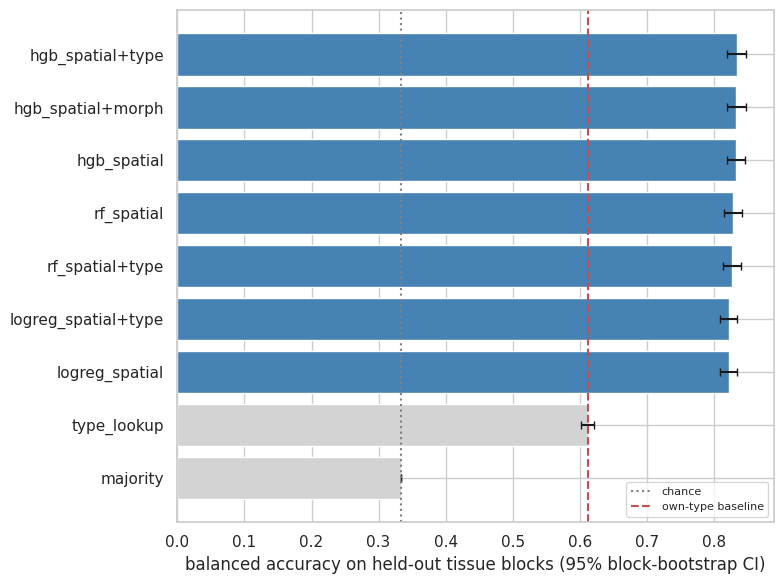

In [6]:
def fold_metrics(name):
    rows = []
    for f in FOLDS:
        te = splits[f][1]; p = OOF[name]["proba"][te]; yt = y[te]; pr = p.argmax(1)
        rows.append({"model": name, "fold": f, "n_test": len(te), "balanced_accuracy": balanced_accuracy_score(yt, pr),
                     "macro_f1": f1_score(yt, pr, average="macro"), "accuracy": accuracy_score(yt, pr),
                     "log_loss": log_loss(yt, np.clip(p, 1e-9, 1), labels=list(range(K))),
                     "ordinal_mae": np.mean(np.abs(ord_rank[yt] - ord_rank[pr]))})
    return rows
FM = pd.DataFrame([r for n in MODELS for r in fold_metrics(n)])
FM.round(5).to_csv(TAB_DIR / "ml_fold_metrics.csv", index=False)

W = ml.bootstrap_weights(nb, N5["n_bootstrap"], RNG)
POINT, BOOT = {}, {}
for n in MODELS:
    Cb = ml.block_confusions(y[vi], OOF[n]["pred"][vi], blk_v_codes, nb, K)
    POINT[n] = ml.metrics_from_counts(Cb.sum(0))
    BOOT[n] = ml.metrics_from_counts(np.einsum("rb,bkl->rkl", W, Cb))
ci = lambda a: np.nanpercentile(a, [2.5, 97.5])

summ = []
for n, (kind, fs) in MODELS.items():
    d = FM[FM["model"] == n]
    lo, hi = ci(BOOT[n]["balanced_accuracy"]); flo, fhi = ci(BOOT[n]["macro_f1"])
    summ.append({"model": n, "features": fs, "balanced_accuracy": float(POINT[n]["balanced_accuracy"]), "bal_acc_ci_low": lo, "bal_acc_ci_high": hi,
                 "bal_acc_fold_sd": d["balanced_accuracy"].std(), "macro_f1": float(POINT[n]["macro_f1"]), "f1_ci_low": flo, "f1_ci_high": fhi,
                 "accuracy": float(POINT[n]["accuracy"]), "log_loss": d["log_loss"].mean(), "ordinal_mae": d["ordinal_mae"].mean(),
                 "fit_minutes": OOF[n]["fit_seconds"].sum() / 60})
SUM = pd.DataFrame(summ).sort_values("balanced_accuracy", ascending=False)
display(SUM.round(4)); SUM.round(5).to_csv(TAB_DIR / "ml_model_comparison.csv", index=False)

comps = [("logreg_spatial", "type_lookup"), ("rf_spatial", "type_lookup"), ("hgb_spatial", "type_lookup"), ("hgb_spatial+type", "type_lookup"),
         ("hgb_spatial+type", "hgb_spatial"), ("hgb_spatial", "logreg_spatial"), ("rf_spatial", "hgb_spatial"), ("hgb_spatial+morph", "hgb_spatial")]
rows = []
for a, b in comps:
    diff = BOOT[a]["balanced_accuracy"] - BOOT[b]["balanced_accuracy"]; lo, hi = ci(diff)
    rows.append({"model_A": a, "model_B": b, "diff_bal_acc": float(POINT[a]["balanced_accuracy"] - POINT[b]["balanced_accuracy"]),
                 "ci_low": lo, "ci_high": hi, "A_better_in_pct_of_bootstraps": float((diff > 0).mean() * 100), "excludes_zero": bool(lo > 0 or hi < 0)})
PD_ = pd.DataFrame(rows); display(PD_.round(4)); PD_.round(5).to_csv(TAB_DIR / "ml_paired_comparisons.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 0.5 * len(SUM) + 1.5))
s = SUM.iloc[::-1]
ax.barh(s["model"], s["balanced_accuracy"], xerr=[s["balanced_accuracy"] - s["bal_acc_ci_low"], s["bal_acc_ci_high"] - s["balanced_accuracy"]],
        color=["lightgrey" if m in BASELINES else "steelblue" for m in s["model"]], ecolor="k", capsize=3)
ax.axvline(1 / K, color="grey", ls=":", label="chance"); ax.axvline(float(POINT["type_lookup"]["balanced_accuracy"]), color="C3", ls="--", label="own-type baseline")
ax.set_xlabel("balanced accuracy on held-out tissue blocks (95% block-bootstrap CI)"); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG_DIR / "ml_model_comparison.png", dpi=200); plt.show()

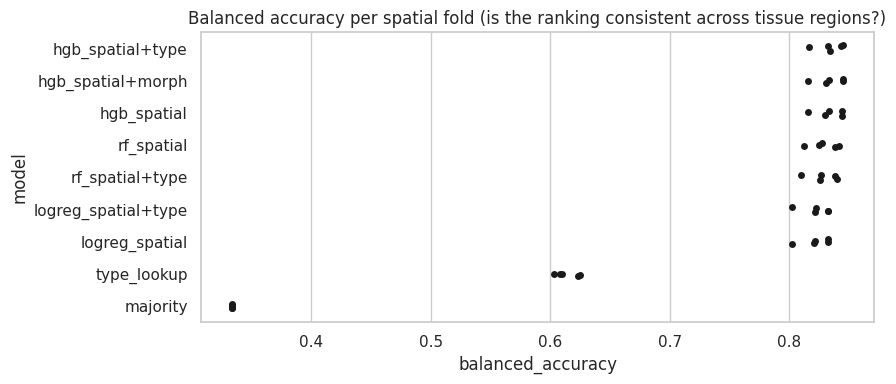

hgb_spatial > type_lookup in 5/5 folds
hgb_spatial+type > type_lookup in 5/5 folds
hgb_spatial+type > hgb_spatial in 4/5 folds


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
order_m = SUM["model"].tolist()
sns.stripplot(data=FM, y="model", x="balanced_accuracy", order=order_m, color="k", size=5, ax=ax)
ax.set_title("Balanced accuracy per spatial fold (is the ranking consistent across tissue regions?)"); plt.tight_layout()
fig.savefig(FIG_DIR / "ml_fold_consistency.png", dpi=200); plt.show()
wins = FM.pivot(index="fold", columns="model", values="balanced_accuracy")
for a, b in [("hgb_spatial", "type_lookup"), ("hgb_spatial+type", "type_lookup"), ("hgb_spatial+type", "hgb_spatial")]:
    print(f"{a} > {b} in {(wins[a] > wins[b]).sum()}/{len(wins)} folds")

## Part 5 — Where do the models succeed or fail?

Best non-baseline model by pooled balanced accuracy: hgb_spatial+type


,model,class,recall,ci_low,ci_high
0,hgb_spatial+type,ME1_Epithelial-rich,0.856,0.826,0.882
1,hgb_spatial+type,ME2_Epithelial/T_cell,0.775,0.746,0.801
2,hgb_spatial+type,ME3_T_cell/Stromal,0.871,0.847,0.893
3,type_lookup,ME1_Epithelial-rich,0.782,0.765,0.798
4,type_lookup,ME2_Epithelial/T_cell,0.159,0.143,0.176
5,type_lookup,ME3_T_cell/Stromal,0.895,0.881,0.907


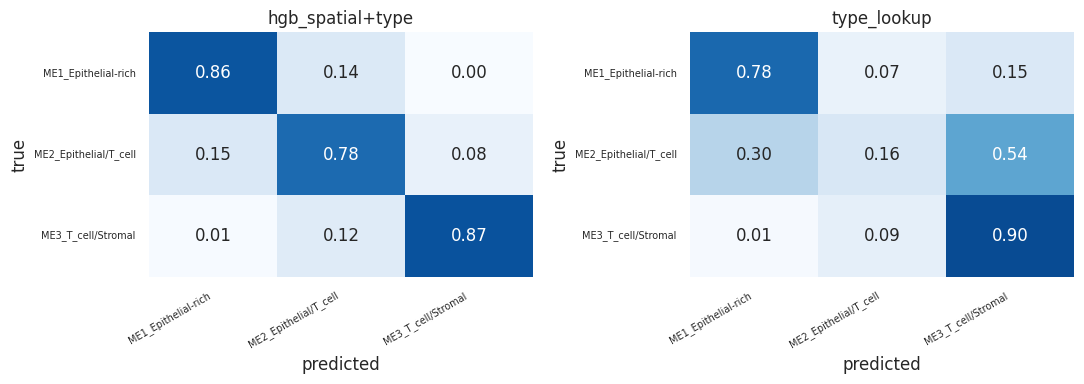

,model,bal_acc_high_margin_90pct,bal_acc_low_margin_10pct
7,hgb_spatial+type,0.865,0.546
8,hgb_spatial+morph,0.865,0.547
6,hgb_spatial,0.865,0.546
4,rf_spatial,0.859,0.560
5,rf_spatial+type,0.858,0.560
3,logreg_spatial+type,0.852,0.562
2,logreg_spatial,0.851,0.562
1,type_lookup,0.621,0.515
0,majority,0.333,0.333


In [8]:
best = SUM[~SUM["model"].isin(BASELINES)].iloc[0]["model"]
print("Best non-baseline model by pooled balanced accuracy:", best)

# per-class recall with CI: best vs own-type baseline
rows = []
for n in [best, "type_lookup"]:
    rec_pt = POINT[n]["recall"]; rec_bs = BOOT[n]["recall"]
    for k in range(K):
        lo, hi = ci(rec_bs[:, k])
        rows.append({"model": n, "class": CLASSES[k], "recall": rec_pt[k], "ci_low": lo, "ci_high": hi})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, n in zip(axes, [best, "type_lookup"]):
    Cm = ml.block_confusions(y[vi], OOF[n]["pred"][vi], blk_v_codes, nb, K).sum(0)
    sns.heatmap(Cm / Cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(n); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", fontsize=7); plt.setp(ax.get_yticklabels(), fontsize=7)
plt.tight_layout(); fig.savefig(FIG_DIR / "ml_confusion_matrices.png", dpi=200); plt.show()

# Boundary cells: is performance lost mostly near class boundaries?
low = A["target_low_margin"].to_numpy()[vi].astype(bool)
rows = []
for n in MODELS:
    pr = OOF[n]["pred"][vi]
    rows.append({"model": n, "bal_acc_high_margin_90pct": balanced_accuracy_score(y[vi][~low], pr[~low]),
                 "bal_acc_low_margin_10pct": balanced_accuracy_score(y[vi][low], pr[low])})
MB = pd.DataFrame(rows).sort_values("bal_acc_high_margin_90pct", ascending=False); display(MB.round(3)); MB.round(4).to_csv(TAB_DIR / "ml_boundary_analysis.csv", index=False)

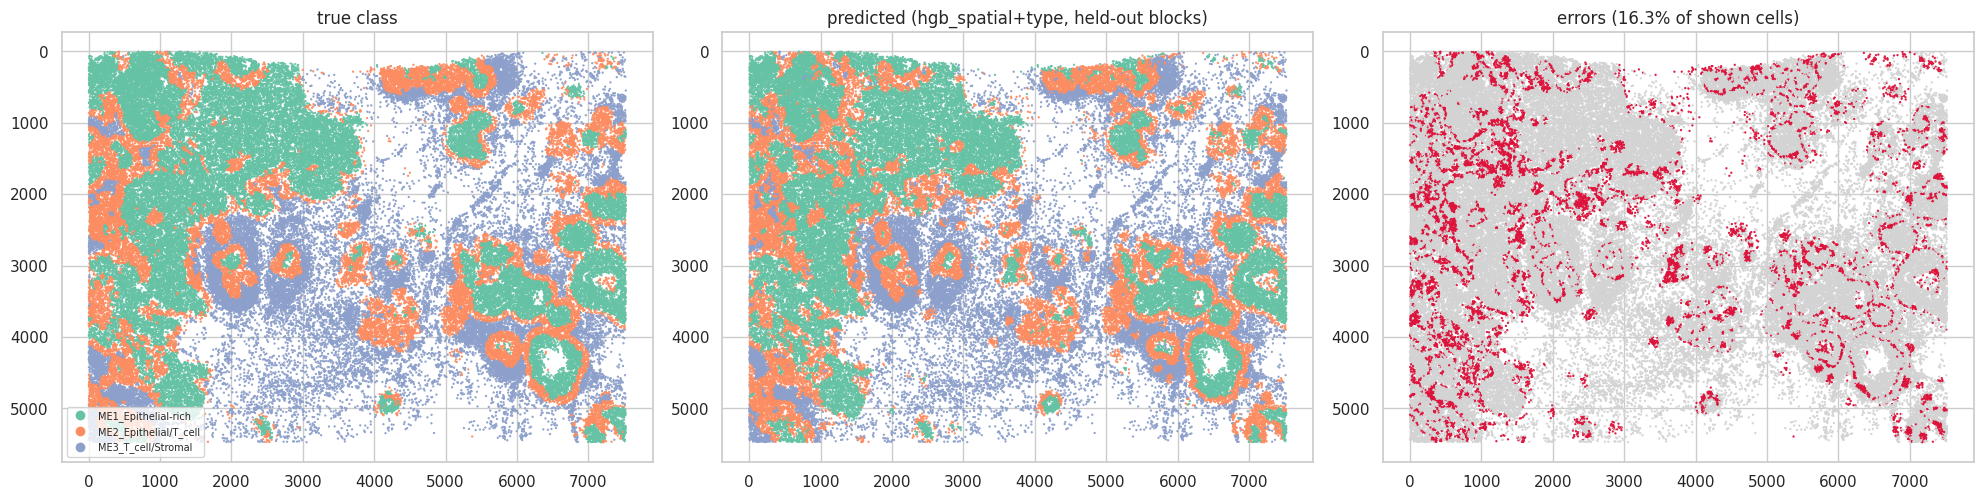

In [9]:
# Spatial map of the best model's out-of-fold predictions
pr = OOF[best]["pred"]; ok = valid
sh = RNG.choice(np.where(ok)[0], min(80000, ok.sum()), replace=False)
pal = dict(zip(range(K), sns.color_palette("Set2", n_colors=K)))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].scatter(xy[sh, 0], xy[sh, 1], c=[pal[v] for v in y[sh]], s=0.4, rasterized=True); axes[0].set_title("true class")
axes[1].scatter(xy[sh, 0], xy[sh, 1], c=[pal[v] for v in pr[sh]], s=0.4, rasterized=True); axes[1].set_title(f"predicted ({best}, held-out blocks)")
wrong = pr[sh] != y[sh]
axes[2].scatter(xy[sh, 0], xy[sh, 1], c=np.where(wrong, "crimson", "lightgrey"), s=0.4, rasterized=True); axes[2].set_title(f"errors ({wrong.mean():.1%} of shown cells)")
for a_ in axes: a_.set_aspect("equal"); a_.invert_yaxis()
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=pal[k], label=CLASSES[k]) for k in range(K)], fontsize=7, loc="lower left")
plt.tight_layout(); fig.savefig(FIG_DIR / "ml_prediction_map.png", dpi=200); plt.show()

## Part 6 — Secondary task: predict the continuous epithelial fraction of the 50–100 µm ring
The classes are cut from a gradient, so a regression target avoids discretisation artefacts. Metrics are R², RMSE (block bootstrap CIs) and Spearman ρ.

[mean_by_type] done
[ridge_spatial] done
[hgb_spatial] done
[hgb_spatial+type] done


,model,R2,R2_ci_low,R2_ci_high,RMSE,RMSE_ci_low,RMSE_ci_high,spearman,spearman_ci_low,spearman_ci_high
0,mean_by_type,0.4966,0.4552,0.5304,0.2371,0.2328,0.2416,0.6261,0.5944,0.6527
1,ridge_spatial,0.8178,0.7951,0.8373,0.1426,0.1371,0.1479,0.9021,0.8890,0.9113
2,hgb_spatial,0.8580,0.8367,0.8763,0.1259,0.1191,0.1321,0.9261,0.9099,0.9377
3,hgb_spatial+type,0.8583,0.8369,0.8766,0.1258,0.1190,0.1320,0.9262,0.9042,0.9354


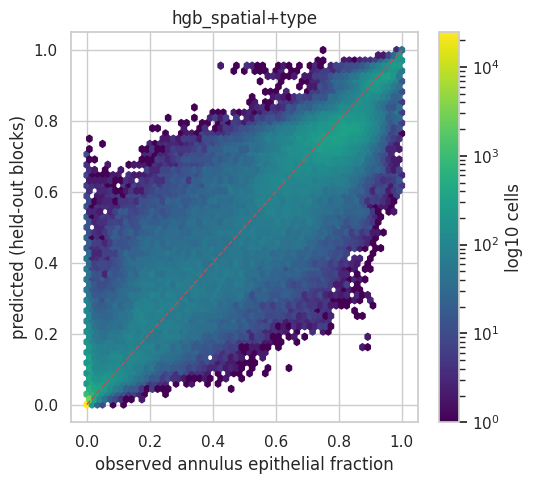

In [10]:
REG = {"mean_by_type": ("typemean", "type_only"), "ridge_spatial": ("ridge", "spatial"),
       "hgb_spatial": ("hgbr", "spatial"), "hgb_spatial+type": ("hgbr", "spatial+type")}
ROOF = {}
for name, (kind, fs) in REG.items():
    ck = CKPT / f"reg_{name}.npz"
    if ck.exists():
        ROOF[name] = np.load(ck)["pred"]; print(f"[{name}] loaded from checkpoint"); continue
    cols = FEATSETS[fs]; pred = np.full(len(T), np.nan)
    for f in FOLDS:
        tr, te, _ = splits[f]
        m = ml.build_model(kind, cols, SEED, kind_params(kind, f)).fit(Xall.iloc[tr][cols], y_reg[tr])
        pred[te] = m.predict(Xall.iloc[te][cols])
    np.savez_compressed(ck, pred=pred); ROOF[name] = pred; print(f"[{name}] done")

rows = []; per_block = {v: np.where(blk_v_codes == v)[0] for v in range(nb)}
for n in REG:
    Sb = ml.block_regression_sums(y_reg[vi], ROOF[n][vi], blk_v_codes, nb)
    r2_pt, rmse_pt = ml.r2_rmse_from_sums(Sb.sum(0)); r2_b, rmse_b = ml.r2_rmse_from_sums(np.einsum("rb,bk->rk", W, Sb))
    rho = spearmanr(y_reg[vi], ROOF[n][vi]).statistic
    rb = []
    for _ in range(N5["spearman_bootstrap"]):
        pick = np.concatenate([per_block[v] for v in RNG.integers(0, nb, nb)]); rb.append(spearmanr(y_reg[vi][pick], ROOF[n][vi][pick]).statistic)
    rows.append({"model": n, "R2": r2_pt, "R2_ci_low": ci(r2_b)[0], "R2_ci_high": ci(r2_b)[1], "RMSE": rmse_pt,
                 "RMSE_ci_low": ci(rmse_b)[0], "RMSE_ci_high": ci(rmse_b)[1], "spearman": rho, "spearman_ci_low": ci(rb)[0], "spearman_ci_high": ci(rb)[1]})
REGT = pd.DataFrame(rows); display(REGT.round(4)); REGT.round(5).to_csv(TAB_DIR / "ml_regression_results.csv", index=False)

bestr = REGT.sort_values("R2", ascending=False).iloc[0]["model"]
fig, ax = plt.subplots(figsize=(5.5, 5))
hb = ax.hexbin(y_reg[vi], ROOF[bestr][vi], gridsize=60, bins="log", cmap="viridis", extent=(0, 1, 0, 1)); ax.plot([0, 1], [0, 1], "r--", lw=1)
ax.set_xlabel("observed annulus epithelial fraction"); ax.set_ylabel("predicted (held-out blocks)"); ax.set_title(bestr); plt.colorbar(hb, label="log10 cells")
plt.tight_layout(); fig.savefig(FIG_DIR / "ml_regression_scatter.png", dpi=200); plt.show()

## Part 7 — Feature importance (held-out, group-aware)
Permutation importance is measured on **held-out test cells of each fold**, as the drop in balanced accuracy. Because composition features at 15 and 30 µm are strongly correlated, single-feature importances understate each feature, so we also permute **whole feature groups jointly**.

fold 0: base balanced accuracy on sample = 0.831
fold 1: base balanced accuracy on sample = 0.815
fold 2: base balanced accuracy on sample = 0.831
fold 3: base balanced accuracy on sample = 0.843
fold 4: base balanced accuracy on sample = 0.845


,mean,std
group,,
dist_nearest_type,0.4066,0.0127
composition_r30,0.1077,0.0100
boundary_r30,0.0010,0.0005
composition_r15,0.0003,0.0024
diversity_r15,0.0002,0.0005
own_cell_type,0.0001,0.0005
density_r30,0.0001,0.0020
diversity_r30,0.0001,0.0015
density_r15,0.0001,0.0001


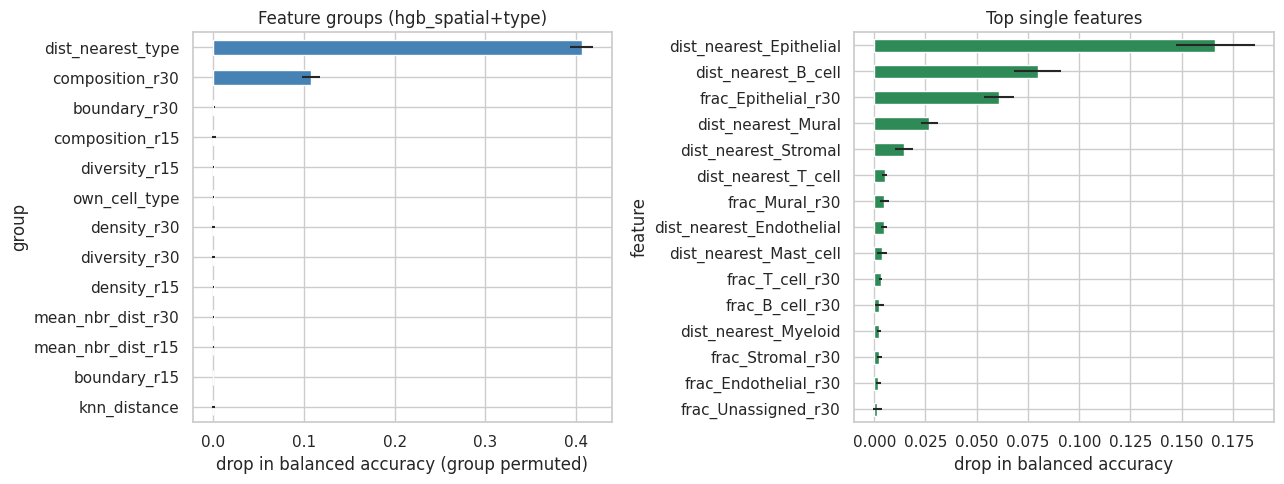

Spearman correlation between permutation importance and Notebook 04 eta2 across 40 spatial features: 0.52


In [11]:
bkind, bfs = MODELS[best]; bcols = FEATSETS[bfs]

def make_groups(cols):
    g = {}
    for r in TD["feature_neighborhood_radii_um"]:
        g[f"composition_r{r}"] = [c for c in cols if c.startswith("frac_") and c.endswith(f"_r{r}")]
        g[f"density_r{r}"] = [c for c in cols if c in (f"n_cells_r{r}", f"density_r{r}")]
        g[f"diversity_r{r}"] = [c for c in cols if c in (f"entropy_r{r}", f"dominant_frac_r{r}")]
        g[f"boundary_r{r}"] = [c for c in cols if c == f"edge_asymmetry_r{r}"]
        g[f"mean_nbr_dist_r{r}"] = [c for c in cols if c == f"mean_nbr_dist_r{r}"]
    g["dist_nearest_type"] = [c for c in cols if c.startswith("dist_nearest_")]
    g["knn_distance"] = [c for c in cols if c.startswith("knn_dist_")]
    g["own_cell_type"] = [c for c in cols if c.startswith("type_")]
    g["morphology"] = [c for c in cols if c in MORPH]
    g = {k: v for k, v in g.items() if v}
    assert sorted(sum(g.values(), [])) == sorted(cols), "group definition does not cover all features"
    return g
GROUPS = make_groups(bcols)

grows, frows = [], []
for f in FOLDS:
    tr, te, _ = splits[f]
    m = ml.build_model(bkind, bcols, SEED, kind_params(bkind, f)).fit(Xall.iloc[tr][bcols], y[tr])
    ts = RNG.choice(te, min(N5["perm_cells_per_fold"], len(te)), replace=False)
    Xt = Xall.iloc[ts][bcols].reset_index(drop=True); yt = y[ts]
    b0, gi = ml.group_permutation_importance(m, Xt, yt, GROUPS, RNG, N5["perm_repeats"])
    _, fi = ml.group_permutation_importance(m, Xt, yt, {c: [c] for c in bcols}, RNG, N5["perm_repeats"])
    grows += [{"fold": f, "group": g, "drop": v[0]} for g, v in gi.items()]
    frows += [{"fold": f, "feature": c, "drop": v[0]} for c, v in fi.items()]
    print(f"fold {f}: base balanced accuracy on sample = {b0:.3f}")

GI = pd.DataFrame(grows).groupby("group")["drop"].agg(["mean", "std"]).sort_values("mean", ascending=False)
FI = pd.DataFrame(frows).groupby("feature")["drop"].agg(["mean", "std"]).sort_values("mean", ascending=False)
display(GI.round(4)); GI.round(5).to_csv(TAB_DIR / "ml_group_importance.csv"); FI.round(5).to_csv(TAB_DIR / "ml_feature_importance.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
GI.iloc[::-1].plot.barh(y="mean", xerr="std", ax=axes[0], legend=False, color="steelblue"); axes[0].set_xlabel("drop in balanced accuracy (group permuted)"); axes[0].set_title(f"Feature groups ({best})")
FI.head(15).iloc[::-1].plot.barh(y="mean", xerr="std", ax=axes[1], legend=False, color="seagreen"); axes[1].set_xlabel("drop in balanced accuracy"); axes[1].set_title("Top single features")
plt.tight_layout(); fig.savefig(FIG_DIR / "ml_feature_importance.png", dpi=200); plt.show()

# Do ML importance and the Notebook 04 statistical ranking agree?
eta = pd.read_csv(TAB_DIR / "feature_class_association_results.csv").set_index("feature")["eta2"]
common = [c for c in FI.index if c in eta.index and c in SPATIAL]
rho_imp = spearmanr(FI.loc[common, "mean"], eta.loc[common]).statistic
print(f"Spearman correlation between permutation importance and Notebook 04 eta2 across {len(common)} spatial features: {rho_imp:.2f}")

## Part 8 — Save results

In [12]:
oof = pd.DataFrame({"cell_id": T["cell_id"].to_numpy(), "cv_fold": fold, "target_valid": valid,
                    "y_true": np.where(valid, np.array(CLASSES, dtype=object)[np.maximum(y, 0)], None)}, index=T.index)
for n in MODELS: oof[f"pred_{n}"] = np.where(OOF[n]["pred"] >= 0, np.array(CLASSES, dtype=object)[np.maximum(OOF[n]["pred"], 0)], None)
for n in REG: oof[f"reg_{n}"] = ROOF[n]
try: oof.to_parquet(PROC_DIR / "ml_oof_predictions.parquet")
except Exception: oof.to_csv(PROC_DIR / "ml_oof_predictions.csv.gz")

lk = float(POINT["type_lookup"]["balanced_accuracy"]); bb = float(POINT[best]["balanced_accuracy"])
gain = PD_[(PD_["model_A"] == best) & (PD_["model_B"] == "type_lookup")]
report = {
    "n_cells_evaluated": int(valid.sum()), "classes": CLASSES, "cv": {"folds": len(FOLDS), "buffer_um": TD["spatial_cv_buffer_um"], "block_um": TD["spatial_cv_block_size_um"]},
    "best_model": best, "best_balanced_accuracy": bb, "best_ci": [float(SUM.iloc[0]["bal_acc_ci_low"]), float(SUM.iloc[0]["bal_acc_ci_high"])] if SUM.iloc[0]["model"] == best else None,
    "own_type_baseline_balanced_accuracy": lk, "chance": 1 / K,
    "best_minus_own_type_baseline": None if gain.empty else {"diff": float(gain.iloc[0]["diff_bal_acc"]), "ci": [float(gain.iloc[0]["ci_low"]), float(gain.iloc[0]["ci_high"])]},
    "best_regression_model": bestr, "best_regression_R2": float(REGT.set_index("model").loc[bestr, "R2"]),
    "top_feature_groups": GI.head(5).index.tolist(), "importance_vs_eta2_spearman": float(rho_imp),
    "settings": N5,
}
json.dump(report, open(REP_DIR / "notebook_05_report.json", "w"), indent=2, default=str)
CONFIG["notebook05"] = N5; json.dump(CONFIG, open(PROJECT_DIR / "configs/config.json", "w"), indent=2)

print("=== Key results (auto-generated; check against the figures) ===")
print(f"1. Chance = {1/K:.3f}; own-type baseline (CV) = {lk:.3f}; best model {best} = {bb:.3f}.")
if not gain.empty: print(f"2. Best minus own-type baseline: {gain.iloc[0]['diff_bal_acc']:+.3f} (95% CI {gain.iloc[0]['ci_low']:+.3f} to {gain.iloc[0]['ci_high']:+.3f}).")
for a, b in [("hgb_spatial+type", "hgb_spatial"), ("hgb_spatial+morph", "hgb_spatial")]:
    r = PD_[(PD_["model_A"] == a) & (PD_["model_B"] == b)]
    if not r.empty: print(f"3. {a} vs {b}: {r.iloc[0]['diff_bal_acc']:+.3f} (CI {r.iloc[0]['ci_low']:+.3f} to {r.iloc[0]['ci_high']:+.3f})")
print(f"4. Most important groups: {GI.head(3).index.tolist()}")
print(f"5. Regression: best {bestr}, R2 = {REGT.set_index('model').loc[bestr, 'R2']:.3f}")
print("Saved: ml_model_comparison.csv, ml_paired_comparisons.csv, ml_fold_metrics.csv, ml_boundary_analysis.csv, ml_regression_results.csv, importance tables, ml_oof_predictions, notebook_05_report.json")

=== Key results (auto-generated; check against the figures) ===
1. Chance = 0.333; own-type baseline (CV) = 0.612; best model hgb_spatial+type = 0.834.
2. Best minus own-type baseline: +0.222 (95% CI +0.209 to +0.234).
3. hgb_spatial+type vs hgb_spatial: +0.001 (CI +0.000 to +0.001)
3. hgb_spatial+morph vs hgb_spatial: +0.000 (CI -0.000 to +0.001)
4. Most important groups: ['dist_nearest_type', 'composition_r30', 'boundary_r30']
5. Regression: best hgb_spatial+type, R2 = 0.858
Saved: ml_model_comparison.csv, ml_paired_comparisons.csv, ml_fold_metrics.csv, ml_boundary_analysis.csv, ml_regression_results.csv, importance tables, ml_oof_predictions, notebook_05_report.json


## Reading these results (and what Notebook 06 must still do)
* **"Beats the baseline" means the paired block-bootstrap CI of the difference excludes 0** — not that the bars look different.
* A gain of `spatial+type` over `type_lookup` answers the research question *given the cell's own label*. A gain of `spatial` alone over `type_lookup` shows that neighborhood alone carries more than identity.
* Cell types come from expression, so own-type is expression-derived (circularity noted in Notebook 02). **Notebook 06** adds an *expression-only* and a *combined* model to quantify what spatial features add beyond the transcriptome itself.
* Errors concentrate near class boundaries and in the middle class by construction (Notebook 04 margins). Report the boundary table, not just overall accuracy.
* **Notebook 06 stress tests still to run:** a coordinates-only model under random vs spatial CV (to demonstrate leakage), different feature radii, buffer sizes and block sizes, and a repeat with low-margin cells removed.
* One tissue section: block-level CIs reflect within-section variation only, not patient-to-patient variation.

## Checklist before Notebook 06
- [ ] All unit tests passed (metrics, split integrity, 100 µm buffer)
- [ ] `ml_model_comparison.png`: ordering baselines < linear < trees makes sense; check whether `rf` and `hgb` differ meaningfully
- [ ] `ml_paired_comparisons.csv`: which comparisons exclude 0?
- [ ] `ml_boundary_analysis.csv`: accuracy on the 90% high-margin cells vs the 10% boundary cells
- [ ] Feature groups at the top of importance are biologically sensible (composition / epithelial distance)
- [ ] Checkpoints exist in `data/processed/ml_checkpoints/` (delete the folder to retrain from scratch)